In [2]:
%cd ../.
import os, sys
sys.path.insert(0, os.path.expanduser('~/CDD_Vault_API/python'))  # CDD Vault API (get_df)

/home/gtamo/Px_interface


In [3]:
%load_ext autoreload
%autoreload 2

import os, re, gc, ctypes, json, time, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from datetime import date
from rdkit import Chem
import yaml
import joblib
from tqdm import tqdm
from types import SimpleNamespace
tqdm.pandas()

from pathlib import Path

import boto3
import psycopg2

# local modules
import python.functions as fn
import python.Px_interface as px
from get_library import get_df   # CDD Vault collection export

# pandas display options:
pd.set_option('display.max_colwidth', None)

## Establish db connection

In [4]:
## params and the validation table of the px database
CONFIG = 'config/config.yaml'

# config keys as attributes: RDS_HOST, RDS_DATABASE, RDS_CRED_FILE, RDS_CA_BUNDLE
params = px.PARAMS(CONFIG).load_params()

# validation experiments: the glues table
glues = fn.rds_table('px_fbx_glues', params.RDS_HOST, params.RDS_DATABASE,
                     params.RDS_CRED_FILE, params.RDS_CA_BUNDLE)   #_> df=cols:[id,pg,uniquecontrast,logfc,pvalue,adjpval,significant,genes]
print(glues.shape)
glues.head(3)

> Dropbox backend: rclone
(1454306, 8)


,id,pg,uniquecontrast,logfc,pvalue,adjpval,significant,genes
0,1,A0A024RBG1,SRB.0002108.001_vs_SRB.0002108.001_complement_Pw105VM_WT,0.310148,0.018744,0.504234,0,NUDT4B
1,2,A0A024RBG1;Q9NZJ9-2,SRB.0000519.002_vs_SRB.0000519.002_complement_Pw144VM_KO,0.194539,0.060745,0.959845,0,NUDT4B;NUDT4
2,3,A0A024RBG1;Q9NZJ9-2,SRB.0000519.002_vs_SRB.0000519.002_complement_Pw144VM_BIND,-0.063056,0.644148,0.999810,0,NUDT4B;NUDT4


In [4]:
## show GLTP significance:
COMPOUND = 'SRB.0009625.'                     # contrast prefix: both batches
GENES    = ['GLTP', 'PDCD2L', 'STAT2']        # GLTP and the report targets

# the compound's experiments with a plate in the name, newest upload, plate from the name
v = (glues[glues['uniquecontrast'].str.startswith(COMPOUND) & glues['uniquecontrast'].str.contains('_complement_')]
     .sort_values('id').drop_duplicates(['uniquecontrast', 'genes', 'pg'], keep='last')
     .assign(plate=lambda x: x['uniquecontrast'].str.extract(r'_complement_(.+)$')[0].str.replace('_', '')))

# logfc, adjpval and the significant flag per gene and plate
v[v['genes'].isin(GENES)].pivot_table(index='genes', columns='plate', values=['logfc', 'adjpval', 'significant'],
                                      aggfunc={'logfc': 'mean', 'adjpval': 'min', 'significant': 'max'}).head(3)

adjpval                                                 logfc  \
plate    DG45VDA01KO   DG45VDA01WT     Pw145VDKO     Pw145VDWT DG45VDA01KO   
genes                                                                        
GLTP    4.510207e-07  4.393738e-05  8.519490e-07  6.479477e-09   -2.038047   
PDCD2L  9.945564e-01  1.697540e-22  9.839253e-01  1.949017e-20    0.009431   
STAT2   9.097033e-01  1.717279e-07  9.597051e-01  3.428698e-16    0.079204   

                                       significant                        \
plate  DG45VDA01WT Pw145VDKO Pw145VDWT DG45VDA01KO DG45VDA01WT Pw145VDKO   
genes                                                                      
GLTP     -1.760164 -1.772933 -1.884783           1           1         1   
PDCD2L   -2.004890  0.046312 -1.629466           0           1         0   
STAT2    -0.651540 -0.070834 -0.863081           0           0         0   

                  
plate  Pw145VDWT  
genes             
GLTP           1  
PDCD2L         1  
STAT2          0

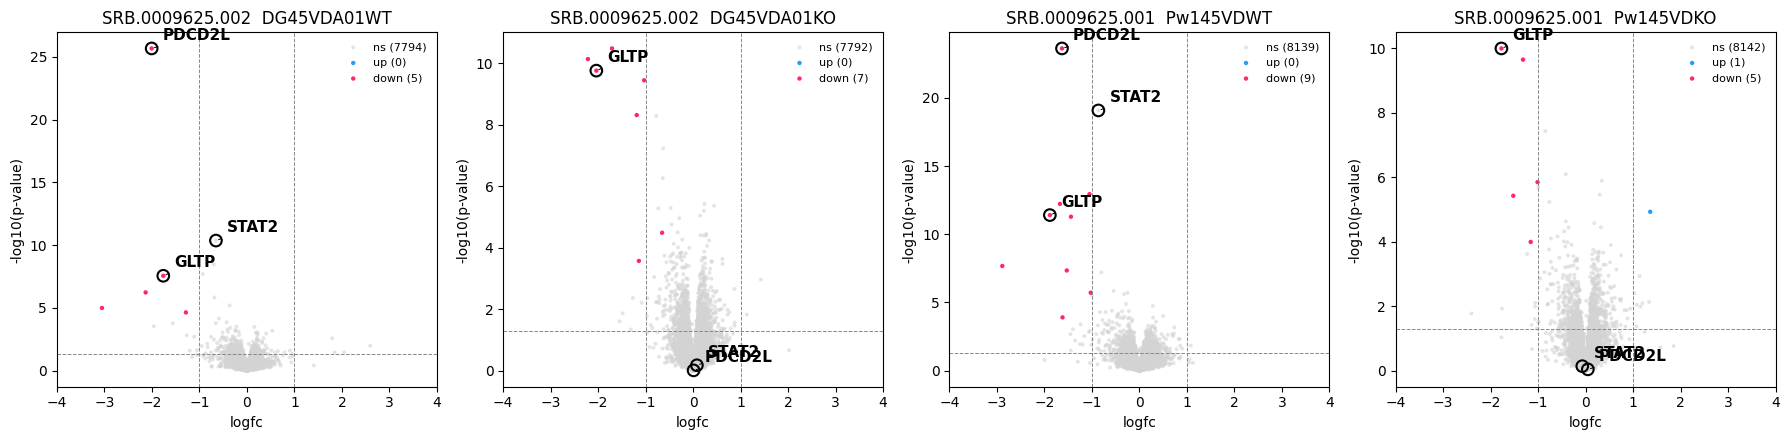

In [5]:
## volcano per validation plate: the database flag in colour, GLTP and the targets ringed
XLIM = (-4, 4)                                # logfc axis

# WT then KO of each plate stem
plates = sorted(v['plate'].unique(), key=lambda p: (p[:-2], p[-2:] != 'WT'))

# one volcano per plate
fig, axes = plt.subplots(1, len(plates), figsize=(4.5 * len(plates), 4.5))
for ax, plate in zip(axes, plates):
    fn.plot_volcano(v, plate, GENES, key='plate', sig_col='significant', xmin=XLIM[0], xmax=XLIM[1], ax=ax,
                    title=f"{v.loc[v['plate'] == plate, 'uniquecontrast'].iloc[0].split('_vs_')[0]}  {plate}")

In [7]:
## query database for px glues:
SQL = 'SELECT * FROM px_ms_score_glues' # px_fbx_msscore # px_ms_score_glues #  any read-only query: a table, a filter, a join

# the query result as a DataFrame
df = fn.rds_query(SQL, params.RDS_HOST, params.RDS_DATABASE,
                  params.RDS_CRED_FILE, params.RDS_CA_BUNDLE)   #_> df=cols:[id,target,msscore,associationscore]
print(df.shape)
df.head(3)

(40, 4)


,id,target,msscore,associationscore
0,1,ADH5,11.623510,0.603875
1,2,ARHGEF16,59.873774,0.518815
2,3,ATAD2B,79.835697,0.413954


In [10]:
len(df.genes.unique())

3038

In [34]:
df[df['genes']=='HSPB11']

,id,uniquecontrast,plate,genes,pg,logfc,pvalue,significant,pvaluelog,ms_score,ms_score_percent,activity,geneslabel
1205,1206,SRB.0011320.001_vs_SRB.0011320.001_complement_Pw233,Pw233,HSPB11,Q9Y547,-1.07833,2.121090e-23,1,22.673441,24.449452,18.277875,Low (2-10),NaN


In [11]:
## show MS score from Dropbox FBX:
KIND = 'MSSCORE'      # the FBX export to stack

# the csv of each tranche folder
csvs = [f for t in params.dbx_glob(params.FBX_DIR, '[0-9]*/')
        for f in params.dbx_glob(t, f'*_{KIND}*.csv')]   #_> list[str]=[FBX_DIR/20260601/20260601_FBX_MSSCORE.csv,...]

# one frame, with the tranche of each row
fbx_ms = pd.concat([pd.read_csv(params.dbx(f), float_precision='round_trip').assign(tranche=f.split('/')[-2])
                    for f in csvs], ignore_index=True)   #_> df=cols:[id,uniquecontrast,plate,genes,pg,ms_score,ms_score_percent,activity,...,tranche,associationscore]
print(fbx_ms.shape)
fbx_ms.head(3)

(340042, 13)


,id,uniquecontrast,plate,genes,pg,ms_score,ms_score_percent,activity,association_score,genetic_score,literature_score,tranche,associationscore
0,57627,SRB.0000615.001_vs_SRB.0000615.001_complement_Pw50,Pw50,COQ2,Q96H96;Q96H96-3,7.773390,4.463080,Low (2-10),0.804655,0.929525,0.539777,20260601,NaN
1,57628,SRB.0000615.001_vs_SRB.0000615.001_complement_Pw50,Pw50,TMEM101,Q96IK0,6.707688,3.479123,Low (2-10),0.193600,0.318458,0.607931,20260601,NaN
2,57629,SRB.0000615.001_vs_SRB.0000615.001_complement_Pw50,Pw50,ARID5B,Q14865,7.891245,4.571896,Low (2-10),0.582739,0.874504,0.924602,20260601,NaN


In [ ]:
fbx_ms

In [13]:
len((fbx_ms.genes.unique()))

10288

In [17]:
gr = fbx_ms.groupby('genes')['ms_score'].max().reset_index().sort_values('ms_score',ascending=False)

In [18]:
gr[gr['genes']=='BCL6']

,genes,ms_score
897,BCL6,76.586891


In [19]:
## Get genes from the legacy April-May data:
EXPORTS = [(params.RAW_PROTEOMICS_PATH, params.CLEAN_PROTEOMICS_PATH, 'serac'),    # 2026-04-29
           (params.PX_20260520_DB, params.PX_20260520_CDDVAULT, 'cddvault'),       # 2026-05-20
           (params.PX_20260529_DB, params.PX_20260529_CDDVAULT, 'cddvault')]       # 2026-05-29

# df_raw of the three exports, with the exact p
leg = pd.concat([fn.load_proteomics_data(params.dbx(r), params.dbx(m), mode=k, verbose=False)[0]
                 for r, m, k in EXPORTS], ignore_index=True).dropna()   #_> df=cols:[MoleculeBatchID,MSPlate,genes,pg,logfc,pvalue,...]

# ms score of the significant down rows, not clipped
leg_ms = fn.ms_score_rows(leg.rename(columns={'MSPlate': 'plate'}))   #_> df=cols:[uniquecontrast,plate,genes,pg,ms_score]
print(leg_ms.shape)
leg_ms.head(3)

/home/gtamo/Px_interface/python/functions.py:37: DtypeWarning: Columns (0: MSPlate) have mixed types. Specify dtype option on import or set low_memory=False.
  _ot_session._s = s
/home/gtamo/Px_interface/python/functions.py:46: UserWarning: Parsing dates in %d.%m.%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  payload = r.json()


(40765, 5)


,uniquecontrast,plate,genes,pg,ms_score
0,X1609.001_vs_DMSO_Plate1,Plate1,SLC31A1,O15431,8.521388
1,X1609.001_vs_DMSO_Plate1,Plate1,NMB,P08949,5.209413
2,X1609.001_vs_DMSO_Plate1,Plate1,FBLL1,A6NHQ2,5.932926


In [25]:
gr_leg = leg_ms.groupby('genes')['ms_score'].max().reset_index().sort_values('ms_score')
gr_leg[~gr_leg['genes'].isin(gr['genes'])]

,genes,ms_score
6219,SNCA,1.772842
1850,DOCK11,1.842320
4743,PGBD1,2.019419
4908,PLK4,2.020011
3964,MRPL36,2.131018
...,...,...
7774,ZNF625,100.301059
314,ANKRD1,108.205355
7691,ZNF317,128.162732
4828,PIM3,132.450663


#### Opentarget:

In [29]:
fbx_ms

,id,uniquecontrast,plate,genes,pg,ms_score,ms_score_percent,activity,association_score,genetic_score,literature_score,tranche,associationscore
0,57627,SRB.0000615.001_vs_SRB.0000615.001_complement_Pw50,Pw50,COQ2,Q96H96;Q96H96-3,7.773390,4.463080,Low (2-10),0.804655,0.929525,0.539777,20260601,NaN
1,57628,SRB.0000615.001_vs_SRB.0000615.001_complement_Pw50,Pw50,TMEM101,Q96IK0,6.707688,3.479123,Low (2-10),0.193600,0.318458,0.607931,20260601,NaN
2,57629,SRB.0000615.001_vs_SRB.0000615.001_complement_Pw50,Pw50,ARID5B,Q14865,7.891245,4.571896,Low (2-10),0.582739,0.874504,0.924602,20260601,NaN
3,57630,SRB.0000615.001_vs_SRB.0000615.001_complement_Pw50,Pw50,KDM1B,Q8NB78,111.247261,100.000000,Low (2-10),0.377864,0.620037,0.718814,20260601,NaN
4,57631,SRB.0000615.001_vs_SRB.0000615.001_complement_Pw50,Pw50,LRRFIP1,Q32MZ4-4,7.190526,3.924925,Low (2-10),0.596193,0.739109,0.892401,20260601,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
340037,11574,SRB.0013952.001_vs_SRB.0013952.001_complement_DG30_B01_Pw293,DG30_B01_Pw293,SNF8,Q96H20,28.519205,38.430168,Low (2-10),NaN,NaN,NaN,20261006,0.630082
340038,11575,SRB.0013952.001_vs_SRB.0013952.001_complement_DG30_B01_Pw293,DG30_B01_Pw293,PLCXD1,Q9NUJ7,4.940597,3.295874,Low (2-10),NaN,NaN,NaN,20261006,0.018927
340039,11576,SRB.0013952.001_vs_SRB.0013952.001_complement_DG30_B01_Pw293,DG30_B01_Pw293,REXO1,Q8N1G1,4.607434,2.799431,Low (2-10),NaN,NaN,NaN,20261006,0.373609
340040,11577,SRB.0013954.001_vs_SRB.0013954.001_complement_DG30_B01_Pw293,DG30_B01_Pw293,GPAM,Q9HCL2,25.313431,33.653269,Low (2-10),NaN,NaN,NaN,20261006,0.562349


In [30]:
## get associatiaon score from FBX:
# one association column: associationscore in the 20261006 export
fbx_ms['association_score'] = fbx_ms['association_score'].fillna(fbx_ms['associationscore'])

# one row per gene
fbx_assoc = fbx_ms[['genes', 'association_score']].dropna().drop_duplicates('genes').reset_index(drop=True)
print(fbx_assoc.shape)
fbx_assoc.head(3)

(10045, 2)


,genes,association_score
0,COQ2,0.804655
1,TMEM101,0.193600
2,ARID5B,0.582739


In [32]:
fbx_assoc[fbx_assoc['genes']=='HSPB11']

,genes,association_score


In [27]:
## get Opentargets from RDS:
SQL = 'SELECT * FROM opentarget'       # one row per gene

# the opentarget table as a DataFrame
ot_df = fn.rds_query(SQL, params.RDS_HOST, params.RDS_DATABASE,
                     params.RDS_CRED_FILE, params.RDS_CA_BUNDLE)   #_> df=cols:[scoreaffected_pathway,...,associationscore,...,approvedsymbol,...,nameassociation,id]
print(ot_df.shape)
# ot_df.head(3)

(30468, 17)
